### ***Descrição do problema***
O shopping quer entender melhor o perfil dos seus clientes para oferecer serviços e promoções mais personalizadas. No entanto, os dados coletados dos clientes, como idade, renda anual e pontuação de gasto, não possuem rótulos ou classificações que facilitem a análise.

Nosso objetivo é usar o algoritmo K-Means para agrupar esses clientes em diferentes categorias com base em seus comportamentos e características. Dessa forma, o shopping poderá identificar diferentes grupos de consumidores, como aqueles que têm um alto potencial de compra ou os que precisam de um incentivo para aumentar seus gastos.


Nesta aula, vamos aprender a usar o algoritmo de agrupamento K-Means em um dataset real. K-Means é um algoritmo de aprendizado não supervisionado, o que significa que ele pode ser utilizado em dados que não possuem rótulos. Vamos utilizar um exemplo prático para criar um dataset rotulado a partir de dados sem rótulos. Escolhemos um dataset que contém dados sobre clientes de um shopping para aplicar o K-Means e entender o perfil dos clientes.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns
import joblib
#pip install joblib

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [4]:
dataset = pd.read_csv('/content/drive/MyDrive/dataset/Mall_Customers.csv')

In [5]:
# Explorando os dados
print(dataset.head())

   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [6]:
# Selecionando apenas as colunas relevantes para o K-Means (por exemplo, Renda Anual e Pontuação de Gasto)
X = dataset.iloc[:, [3, 4]].values

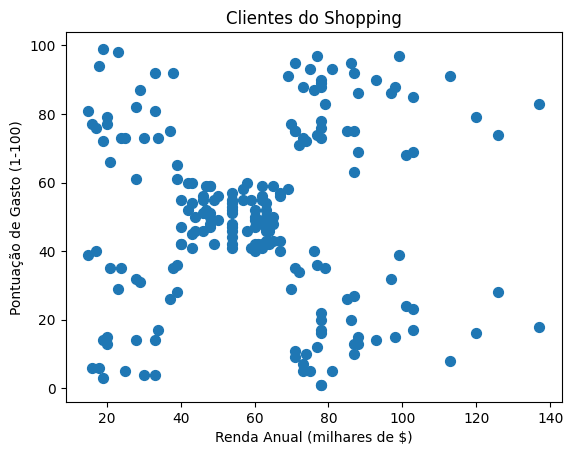

In [7]:
# Visualizando a dispersão dos dados
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.xlabel('Renda Anual (milhares de $)')
plt.ylabel('Pontuação de Gasto (1-100)')
plt.title('Clientes do Shopping')
plt.show()

In [8]:
# Encontrando o número ótimo de clusters usando o método Elbow
inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)


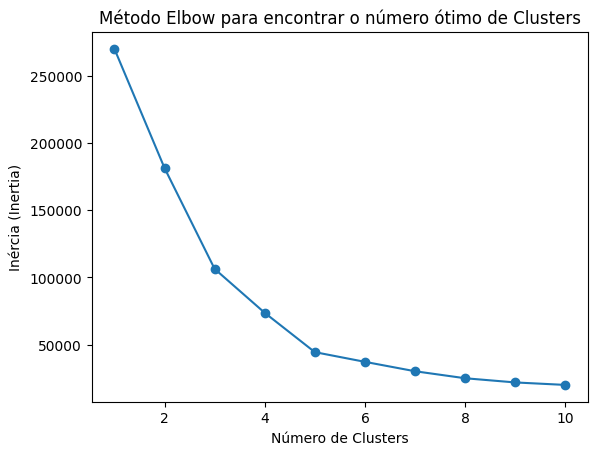

In [9]:
# Plotando o gráfico do método Elbow
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Número de Clusters')
plt.ylabel('Inércia (Inertia)')
plt.title('Método Elbow para encontrar o número ótimo de Clusters')
plt.show()

In [10]:
# A partir do gráfico, assumimos que o número ótimo de clusters é 5
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, init='k-means++', max_iter=300, n_init=10, random_state=42)
y_kmeans = kmeans.fit_predict(X)

In [11]:
y_kmeans

array([4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2,
       4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 0,
       4, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 3, 1, 0, 1, 3, 1, 3, 1,
       0, 1, 3, 1, 3, 1, 3, 1, 3, 1, 0, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1], dtype=int32)

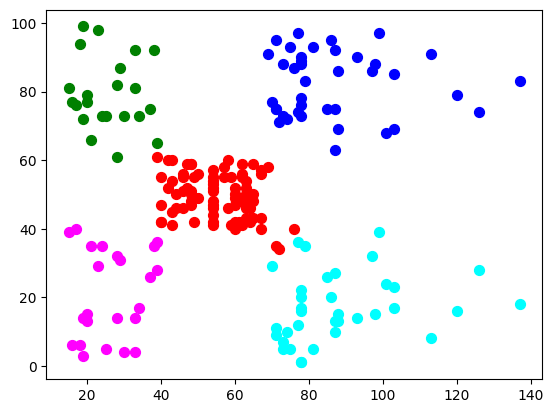

In [12]:
# Visualizando os clusters
plt.scatter(X[y_kmeans == 0, 0], X[y_kmeans == 0, 1], s=50, c='red', label='Cluster 1')
plt.scatter(X[y_kmeans == 1, 0], X[y_kmeans == 1, 1], s=50, c='blue', label='Cluster 2')
plt.scatter(X[y_kmeans == 2, 0], X[y_kmeans == 2, 1], s=50, c='green', label='Cluster 3')
plt.scatter(X[y_kmeans == 3, 0], X[y_kmeans == 3, 1], s=50, c='cyan', label='Cluster 4')
plt.scatter(X[y_kmeans == 4, 0], X[y_kmeans == 4, 1], s=50, c='magenta', label='Cluster 5')

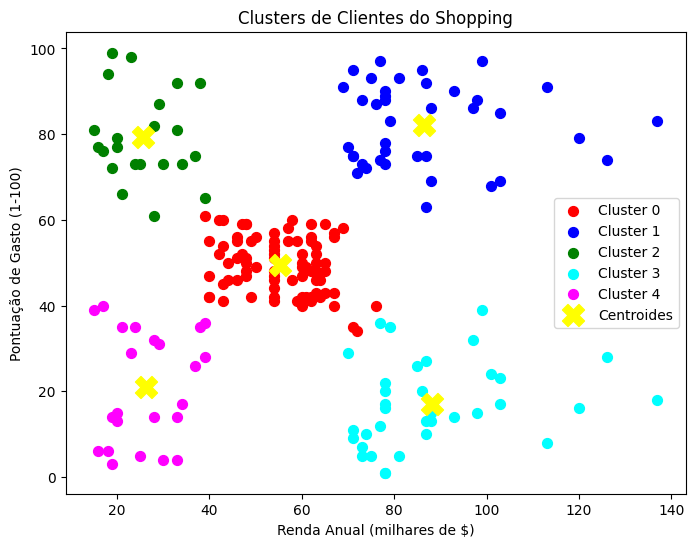

In [13]:
# Visualizando os clusters
plt.figure(figsize=(8,6))

plt.scatter(X[y_kmeans == 0, 0], X[y_kmeans == 0, 1], s=50, c='red', label='Cluster 0')
plt.scatter(X[y_kmeans == 1, 0], X[y_kmeans == 1, 1], s=50, c='blue', label='Cluster 1')
plt.scatter(X[y_kmeans == 2, 0], X[y_kmeans == 2, 1], s=50, c='green', label='Cluster 2')
plt.scatter(X[y_kmeans == 3, 0], X[y_kmeans == 3, 1], s=50, c='cyan', label='Cluster 3')
plt.scatter(X[y_kmeans == 4, 0], X[y_kmeans == 4, 1], s=50, c='magenta', label='Cluster 4')

# Marcando os centroides no mesmo gráfico
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=250,
    c='yellow',
    marker='X',
    label='Centroides'
)

plt.xlabel('Renda Anual (milhares de $)')
plt.ylabel('Pontuação de Gasto (1-100)')
plt.title('Clusters de Clientes do Shopping')
plt.legend()
plt.show()

In [14]:
# Salvando o modelo treinado
joblib.dump(kmeans, '/content/drive/MyDrive/dataset/kmeans_model.pkl')

['/content/drive/MyDrive/dataset/kmeans_model.pkl']

In [15]:
# Criando um novo dataset com os rótulos dos clusters gerados
dataset['Cluster'] = y_kmeans


In [16]:
# Salvando o dataset rotulado em um novo arquivo CSV
dataset.to_csv('/content/drive/MyDrive/dataset/Mall_Customers_Rotulado.csv', index=False)

In [17]:
dataset2 = pd.read_csv('/content/drive/MyDrive/dataset/Mall_Customers_Rotulado.csv')

In [18]:
dataset2.head(20)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


In [19]:

# Calculando as Centróides
centroides = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=['Renda', 'Gasto']
)

centroides


,Renda,Gasto
0,55.296296,49.518519
1,86.538462,82.128205
2,25.727273,79.363636
3,88.200000,17.114286
4,26.304348,20.913043


**Cluster 0 — Clientes de Classe Média**

(Renda Média, Gasto Médio)

“Este grupo representa clientes com renda e padrão de consumo intermediários. Eles mantêm um comportamento equilibrado de gasto e são importantes para a estabilidade financeira do negócio.”

**Cluster 1 — Clientes de Alto Valor**

(Renda Alta, Gasto Alto)

“Este cluster reúne clientes com alto poder aquisitivo e alto nível de consumo. São os clientes mais valiosos para o shopping, pois possuem maior potencial de geração de receita.”

**Cluster 2 — Clientes Econômicos**

(Renda Baixa, Gasto Alto)

“Este grupo inclui clientes com renda mais baixa, mas que apresentam alto nível de consumo. Esses clientes tendem a priorizar gastos e podem responder bem a promoções e estratégias de incentivo.”

**Cluster 3 — Clientes Prudentes**

(Renda Alta, Gasto Baixo)

“Clientes com alta renda, mas baixo nível de consumo. Esse perfil indica potencial de crescimento, pois esses clientes podem ser estimulados a gastar mais por meio de estratégias de marketing direcionadas.”

**Cluster 4 — Clientes de Baixo Perfil**

(Renda Baixa, Gasto Baixo)

“Este cluster representa clientes com baixo poder aquisitivo e baixo nível de consumo. São os clientes com menor impacto financeiro para o shopping.”
